<a href="https://colab.research.google.com/github/Killeryoung/ML/blob/main/%D0%9B%D0%A05_%D0%93%D1%83%D1%80%D0%BA%D0%BE_%D0%A4%D0%86%D0%A2_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Daily Weather Time Series Data - Delhi, India**

https://www.kaggle.com/datasets/yug201/daily-climate-time-series-data-delhi-india?select=kaggel_weather_2013_to_2024.csv

**Тема:** Прогнозування часових рядів на основі кліматичних даних

**Мета роботи:**
Навчитися виконувати аналіз часових рядів, проводити дослідницький аналіз даних (EDA), визначати автокореляційні залежності, будувати моделі прогнозування та оцінювати їхню точність.

**Вихідні дані**

Для виконання роботи використовується датасет Daily Climate Time Series Data (Delhi, India) з платформи Kaggle, який містить щоденні кліматичні показники (температура, вологість, опади тощо) за кілька років.


1. Завантажити датасет з Kaggle.

2. Імпортувати дані у середовище Python (Jupyter Notebook або Google Colab).

3. Ознайомитися зі структурою датасету (head(), info(), describe()).

4. Попередня обробка даних

-Перетворити колонку з датою у формат datetime.

-Відсортувати дані за датою.

-Встановити дату як індекс часового ряду.

-Перевірити наявність пропущених значень та за необхідності обробити їх.

5. Дослідницький аналіз даних (EDA)

-Побудувати графік зміни температури у часі.

-Побудувати ковзне середнє значення температури.

-Побудувати гістограму розподілу температури.

-Побудувати boxplot для виявлення можливих викидів.

-Аналіз автокореляції

Побудувати графік автокореляційної функції (ACF).

Побудувати графік часткової автокореляції (PACF).

-Проаналізувати залежність значень часового ряду від попередніх періодів.

6.Підготовка даних для моделювання

-Розділити дані на тренувальну та тестову вибірки (наприклад, 80% / 20%).

7. Побудувати щонайменше три моделі прогнозування:

-ARIMA (класична статистична модель);

-Prophet (модель прогнозування часових рядів від Meta);

-LSTM (нейронна мережа для послідовних даних).

8. Оцінка моделей
Для кожної моделі обчислити метрики:

-MAE (Mean Absolute Error)

-RMSE (Root Mean Squared Error)

-MAPE (Mean Absolute Percentage Error)

8.Візуалізація результатів

-Побудувати графіки прогнозованих та фактичних значень.

-Побудувати порівняльний графік прогнозів усіх моделей.

-Порівняння моделей

-Створити таблицю з метриками точності.

9.Визначити модель, яка показала найкращий результат.

In [52]:
# Імпорт бібліотек
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import MinMaxScaler
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

warnings.filterwarnings("ignore")
plt.style.use("default")

In [53]:
# Завантажте датасет з Kaggle
import kagglehub

path = kagglehub.dataset_download("yug201/daily-climate-time-series-data-delhi-india")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'daily-climate-time-series-data-delhi-india' dataset.
Path to dataset files: /kaggle/input/daily-climate-time-series-data-delhi-india


In [54]:
# Зчитайте датасет у DataFrame та перегляньте дані
df = pd.read_csv(os.path.join(path,"kaggel_weather_2013_to_2024.csv"))
display(df)

,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
0,0,4/14/2013,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
1,1,4/15/2013,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2,2,4/16/2013,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
3,3,4/17/2013,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
4,4,4/18/2013,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3552,3552,11/26/2024,25.8,13.6,18.6,25.8,13.6,18.6,65.9,0.0,...,24,48,1700.22,896.24,1225.74,1700.22,896.24,1225.74,12.2,242.171864
3553,3553,11/27/2024,26.2,12.5,18.4,26.2,12.5,18.4,61.0,0.0,...,24,48,1598.20,762.50,1122.40,1598.20,762.50,1122.40,13.7,236.769595
3554,3554,11/28/2024,25.8,11.5,17.9,25.8,11.5,17.9,63.1,0.0,...,24,48,1627.98,725.65,1129.49,1627.98,725.65,1129.49,14.3,243.117035
3555,3555,11/29/2024,25.0,10.6,18.0,25.0,10.6,18.0,60.0,0.0,...,24,48,1500.00,636.00,1080.00,1500.00,636.00,1080.00,14.4,237.638344


**ДАТА**: Дата спостереження.

**Температура**: tempmax, tempmin, temp.

**Відчутна температура**: feelslikemax, feelslikemin, feelslike.

**Вологість**: Середня відносна вологість.

**Опади**: рrесір, precipprob, precipcover.

**Вітер і тиск**: windspeed, sealevelpressure.

**Умови**: Опис погоди (Ясно, Дощ, Хмарно тощо).

**Похідні показники**: temp_range, heat_index.

Підготовка даних

In [55]:
# Виконайте попередню обробку даних:
# - DATE -> datetime
# - сортування за датою
# - видалення зайвих колонок
# - встановлення DATE як індексу
date_col = "DATE" if "DATE" in df.columns else next((c for c in df.columns if "date" in c.lower()), None)
temp_col = "temp" if "temp" in df.columns else next((c for c in df.columns if "temperature" in c.lower()), None)

if date_col is None or temp_col is None:
    raise ValueError(f"Не вдалося визначити стовпці дати й температури. Наявні колонки: {df.columns.tolist()}")

df[date_col] = pd.to_datetime(df[date_col], errors="coerce")
df[temp_col] = pd.to_numeric(df[temp_col], errors="coerce")
df = df.dropna(subset=[date_col, temp_col]).sort_values(date_col)
df = df.drop_duplicates(subset=[date_col]).set_index(date_col)
df = df.rename(columns={temp_col: "Temperature"})
df["Temperature"] = df["Temperature"].interpolate(method="time").ffill().bfill()
print("Використана колонка дати:", date_col)
print("Використана колонка температури:", temp_col)
print("Період:", df.index.min().date(), "-", df.index.max().date())
display(df[["Temperature"]].head())

Використана колонка дати: DATE
Використана колонка температури: temp
Період: 2013-04-14 - 2024-11-30


,Temperature
DATE,
2013-04-14,28.7
2013-04-15,28.6
2013-04-16,31.7
2013-04-17,29.9
2013-04-18,30.6


In [56]:
# Перегляньте інформацію про структуру датасету
display(df.head())
print("\nІнформація про дані:")
df.info()
print("\nОписова статистика:")
display(df[["Temperature"]].describe())

,Unnamed: 0,tempmax,tempmin,Temperature,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
DATE,,,,,,,,,,,,,,,,,,,,,
2013-04-14,0,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,100,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
2013-04-15,1,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,0,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2013-04-16,2,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,0,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
2013-04-17,3,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,0,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
2013-04-18,4,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,0,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038



Інформація про дані:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3556 entries, 2013-04-14 to 2024-11-30
Data columns (total 28 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             3556 non-null   int64  
 1   tempmax                3556 non-null   float64
 2   tempmin                3556 non-null   float64
 3   Temperature            3556 non-null   float64
 4   feelslikemax           3556 non-null   float64
 5   feelslikemin           3556 non-null   float64
 6   feelslike              3556 non-null   float64
 7   humidity               3556 non-null   float64
 8   precip                 3556 non-null   float64
 9   precipprob             3556 non-null   int64  
 10  precipcover            3556 non-null   float64
 11  windspeed              3556 non-null   float64
 12  sealevelpressure       3556 non-null   float64
 13  conditions             3556 non-null   object 
 14  Year            

,Temperature
count,3556.000000
mean,25.400984
std,7.325185
min,6.500000
25%,19.100000
50%,27.700000
75%,31.000000
max,39.500000


In [57]:
# Перевірте наявність пропущених значень
print("Пропущені значення до остаточної перевірки:")
display(df.isna().sum().to_frame("Кількість пропусків"))
print("Загальна кількість пропусків:", int(df.isna().sum().sum()))

Пропущені значення до остаточної перевірки:


,Кількість пропусків
Unnamed: 0,0
tempmax,0
tempmin,0
Temperature,0
feelslikemax,0
feelslikemin,0
feelslike,0
humidity,0
precip,0
precipprob,0


Загальна кількість пропусків: 0


Графік температури

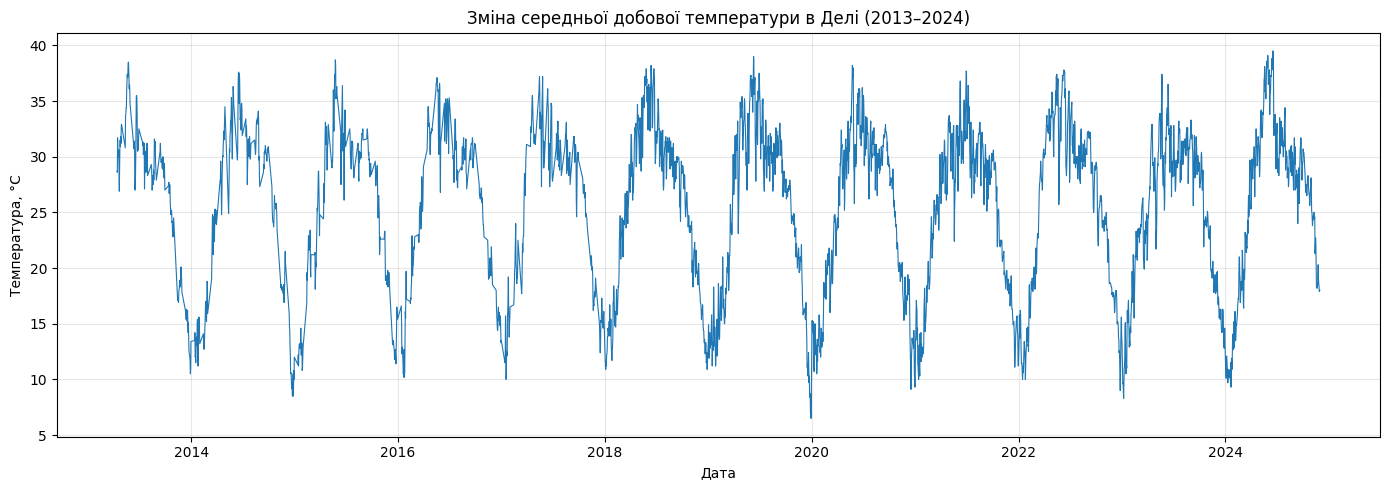

In [58]:
# Побудуйте графік зміни температури у часі
plt.figure(figsize=(14, 5))
plt.plot(df.index, df["Temperature"], linewidth=0.8)
plt.title("Зміна середньої добової температури в Делі (2013–2024)")
plt.xlabel("Дата")
plt.ylabel("Температура, °C")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Ковзне середнє

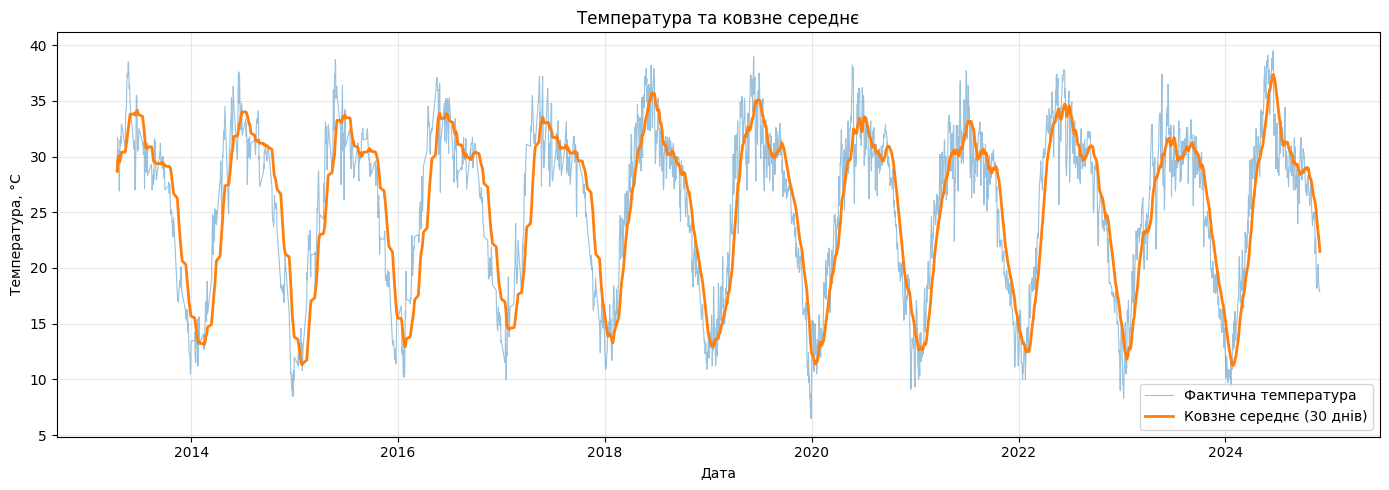

In [59]:
# Обчисліть та візуалізуйте ковзне середнє температури
window = min(30, max(2, len(df)//10))
df["Rolling_mean"] = df["Temperature"].rolling(window=window, min_periods=1).mean()
plt.figure(figsize=(14, 5))
plt.plot(df.index, df["Temperature"], label="Фактична температура", alpha=0.45, linewidth=0.8)
plt.plot(df.index, df["Rolling_mean"], label=f"Ковзне середнє ({window} днів)", linewidth=2)
plt.title("Температура та ковзне середнє")
plt.xlabel("Дата"); plt.ylabel("Температура, °C")
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

Розподіл температури

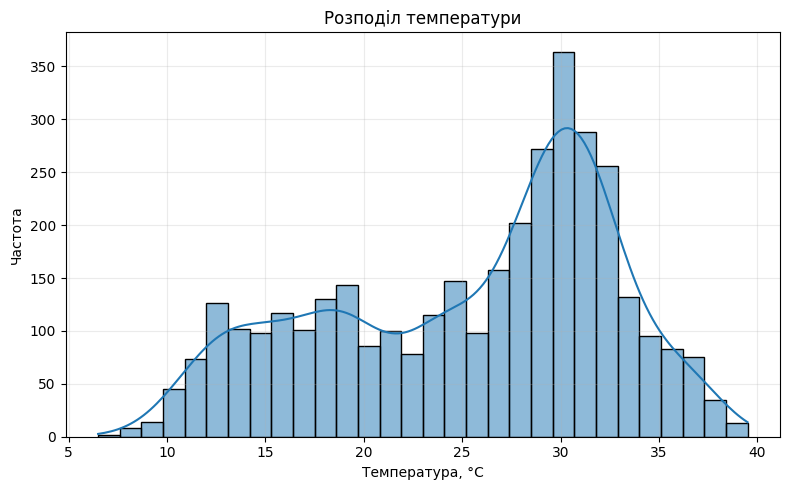

In [60]:
# Побудуйте гістограму розподілу температури
plt.figure(figsize=(8, 5))
sns.histplot(df["Temperature"], bins=30, kde=True)
plt.title("Розподіл температури")
plt.xlabel("Температура, °C"); plt.ylabel("Частота")
plt.grid(True, alpha=0.25); plt.tight_layout(); plt.show()

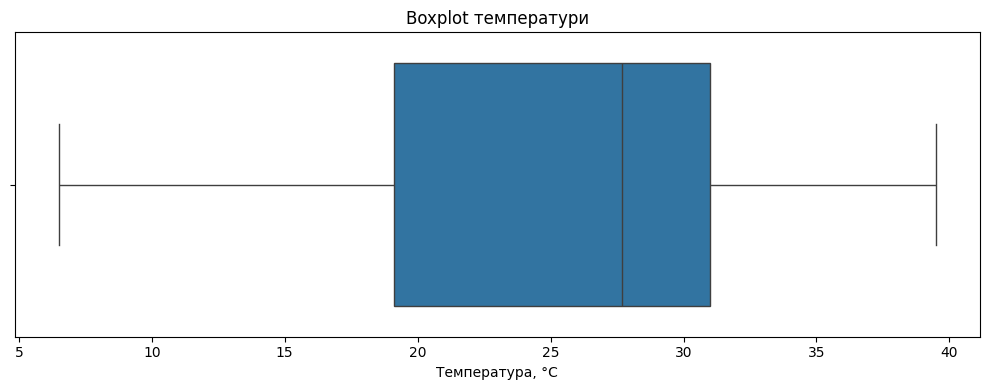

In [61]:
# Побудуйте boxplot температури для аналізу викидів
plt.figure(figsize=(10, 4))
sns.boxplot(x=df["Temperature"])
plt.title("Boxplot температури")
plt.xlabel("Температура, °C")
plt.tight_layout(); plt.show()

Аналіз автокореляції
ACF

PACF

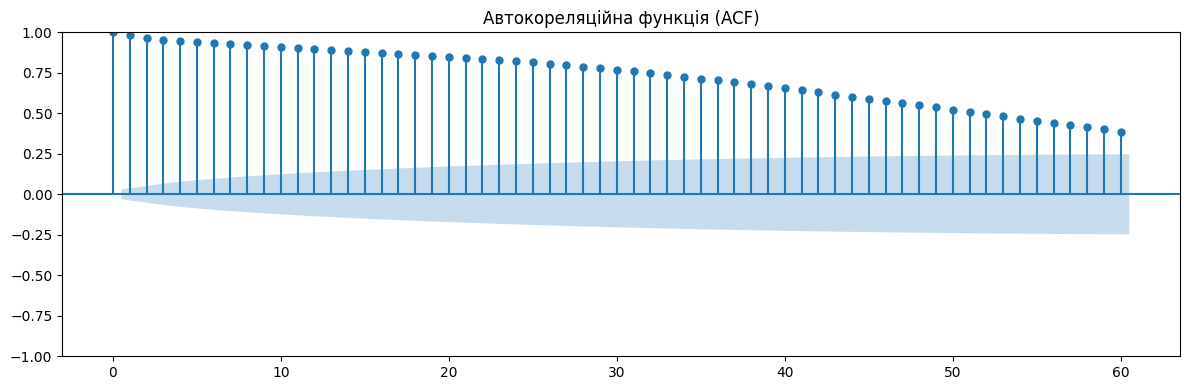

In [62]:
# Побудуйте графік автокореляційної функції (ACF)
series = df["Temperature"].asfreq("D").interpolate("time").ffill().bfill()
lags = min(60, max(1, len(series)//4))
fig, ax = plt.subplots(figsize=(12, 4))
plot_acf(series, lags=lags, ax=ax)
ax.set_title("Автокореляційна функція (ACF)")
plt.tight_layout(); plt.show()

Автокореляційна функція (ACF) використовується для аналізу залежності значень часового ряду від його попередніх значень. Вона відображає ступінь кореляції між значенням показника у певний момент часу та значеннями цього самого показника у попередні моменти часу, які називаються лагами. Побудова графіка автокореляційної функції дозволяє виявити, чи існує статистично значуща залежність між поточним значенням ряду та його попередніми спостереженнями. На такому графіку по горизонтальній осі відкладаються лаги, тобто кількість часових кроків назад, а по вертикальній — значення коефіцієнта автокореляції. Аналіз графіка ACF дає можливість виявити наявність тренду, сезонності або інших закономірностей у часовому ряді, а також використовується для визначення параметрів статистичних моделей прогнозування, зокрема моделі ARIMA.

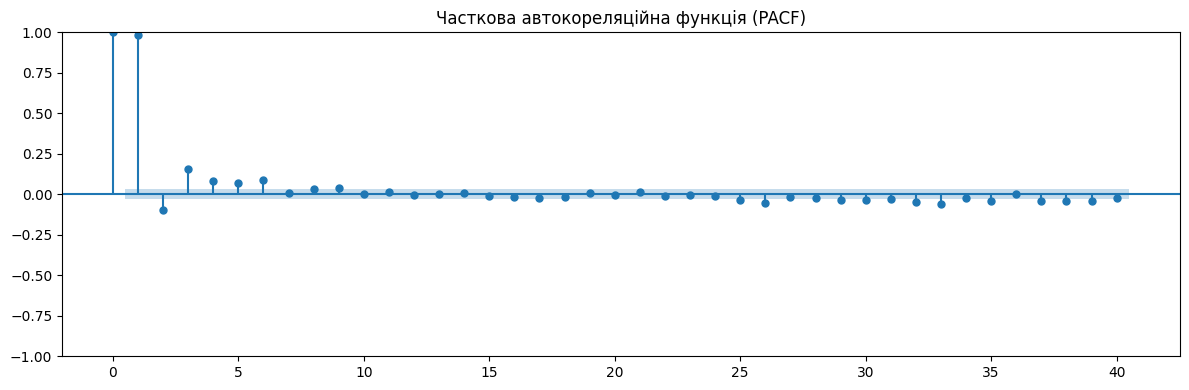

In [63]:
# Побудуйте графік часткової автокореляційної функції (PACF)
fig, ax = plt.subplots(figsize=(12, 4))
plot_pacf(series, lags=min(40, max(1, len(series)//4)), method="ywm", ax=ax)
ax.set_title("Часткова автокореляційна функція (PACF)")
plt.tight_layout(); plt.show()

Часткова автокореляційна функція (PACF) застосовується для більш точного визначення залежності між значеннями часового ряду. На відміну від звичайної автокореляційної функції, PACF вимірює кореляцію між значенням ряду у певний момент часу та значенням у попередній момент часу з конкретним лагом, усуваючи вплив усіх проміжних лагів. Таким чином, часткова автокореляція показує «чисту» залежність між двома спостереженнями часового ряду. Побудова графіка PACF дозволяє визначити, які саме лаги мають статистично значущий вплив на значення ряду. Це є важливим етапом під час побудови моделей прогнозування часових рядів, оскільки аналіз графіка часткової автокореляції використовується для визначення порядку авторегресійної складової моделі, зокрема параметра
𝑝
p у моделі ARIMA.

Усього спостережень: 4249
Тренувальна вибірка: 3399 (80.0%)
Тестова вибірка: 850 (20.0%)
Тренувальний період: 2013-04-14 — 2022-08-03
Тестовий період: 2022-08-04 — 2024-11-30


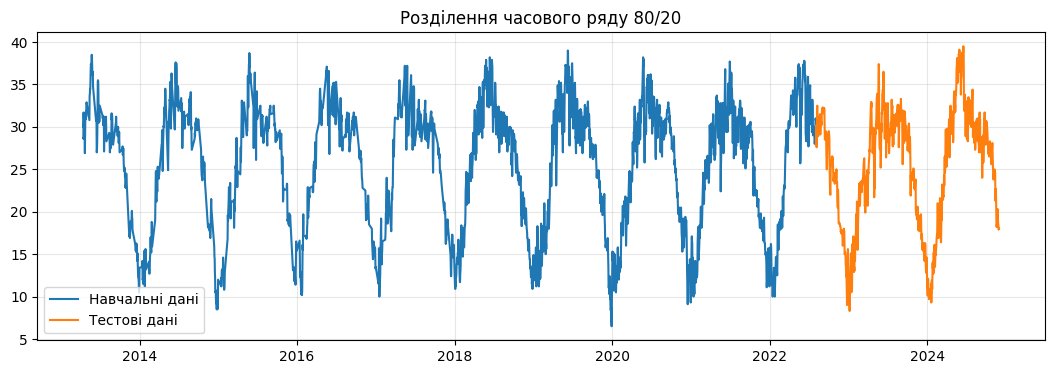

In [64]:
# Сформуйте цільовий часовий ряд та розділіть його на train/test у часовому порядку
y = series.astype(float)
split_idx = int(len(y) * 0.8)
train, test = y.iloc[:split_idx], y.iloc[split_idx:]
print(f"Усього спостережень: {len(y)}")
print(f"Тренувальна вибірка: {len(train)} ({len(train)/len(y):.1%})")
print(f"Тестова вибірка: {len(test)} ({len(test)/len(y):.1%})")
print("Тренувальний період:", train.index.min().date(), "—", train.index.max().date())
print("Тестовий період:", test.index.min().date(), "—", test.index.max().date())
plt.figure(figsize=(13,4))
plt.plot(train.index, train, label="Навчальні дані")
plt.plot(test.index, test, label="Тестові дані")
plt.legend(); plt.title("Розділення часового ряду 80/20"); plt.grid(alpha=.3); plt.show()

ARIMA

https://developer.ibm.com/tutorials/awb-arima-models-in-python/

In [65]:
# Побудуйте та навчіть модель ARIMA. Отримайте прогноз для тестової вибірки
try:
    arima_model = ARIMA(train, order=(2, 1, 2)).fit()
except Exception as e:
    print("ARIMA(2,1,2) не вдалася, використовується ARIMA(1,1,1):", e)
    arima_model = ARIMA(train, order=(1, 1, 1)).fit()
arima_forecast = pd.Series(arima_model.forecast(steps=len(test)), index=test.index, name="ARIMA")
display(arima_forecast.head())


,ARIMA
DATE,
2022-08-04,30.467707
2022-08-05,30.276725
2022-08-06,30.187274
2022-08-07,30.150129
2022-08-08,30.136069


In [66]:
# Виведіть статистичний звіт навченої ARIMA-моделі
print(arima_model.summary())

                               SARIMAX Results                                
Dep. Variable:            Temperature   No. Observations:                 3399
Model:                 ARIMA(2, 1, 2)   Log Likelihood               -5408.879
Date:                Fri, 09 Oct 2026   AIC                          10827.759
Time:                        10:34:29   BIC                          10858.413
Sample:                    04-14-2013   HQIC                         10838.715
                         - 08-03-2022                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.7023      0.067     10.432      0.000       0.570       0.834
ar.L2         -0.1345      0.065     -2.070      0.038      -0.262      -0.007
ma.L1         -0.6217      0.068     -9.134      0.0

сигма 2 : це представляє дисперсію залишкових значень, чим менше, тим краще

логарифмічна правдоподібність : це оцінка максимальної правдоподібності для моделі ARIMA, чим вище, тим краще

aic : міра ступеню відповідності та економності моделі, чим нижче, тим краще

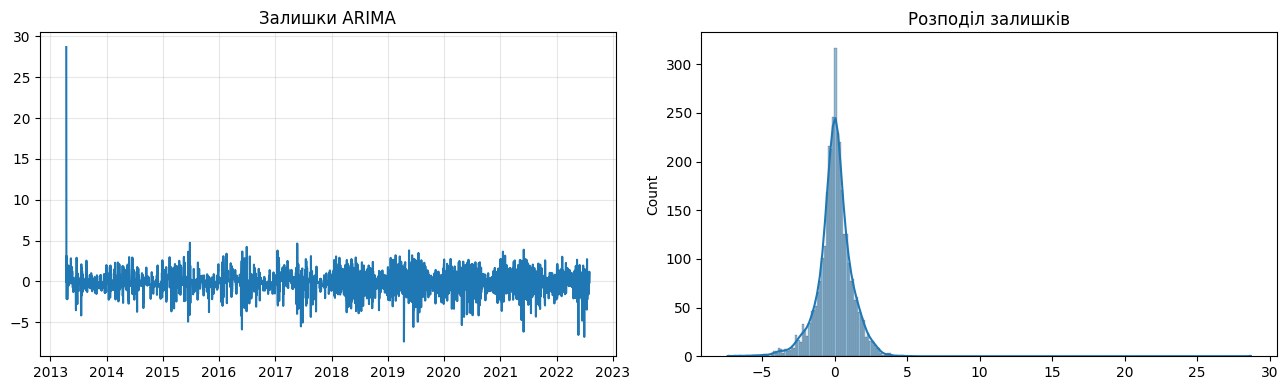

In [67]:
# Проаналізуйте залишки ARIMA-моделі та побудуйте відповідні графіки
residuals = arima_model.resid
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(residuals); axes[0].set_title("Залишки ARIMA"); axes[0].grid(alpha=.3)
sns.histplot(residuals, kde=True, ax=axes[1]); axes[1].set_title("Розподіл залишків")
plt.tight_layout(); plt.show()

In [68]:
# Реалізуйте MAPE та обчисліть MAE, RMSE, MAPE для ARIMA
def calculate_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    nonzero = np.abs(actual) > 1e-8
    mape = np.mean(np.abs((actual[nonzero] - predicted[nonzero]) / actual[nonzero])) * 100 if nonzero.any() else np.nan
    return {"MAE": mae, "RMSE": rmse, "MAPE, %": mape}

metrics = {}
metrics["ARIMA"] = calculate_metrics(test, arima_forecast)
display(pd.DataFrame([metrics["ARIMA"]], index=["ARIMA"]).round(3))

,MAE,RMSE,"MAPE, %"
ARIMA,6.208,8.42,35.866


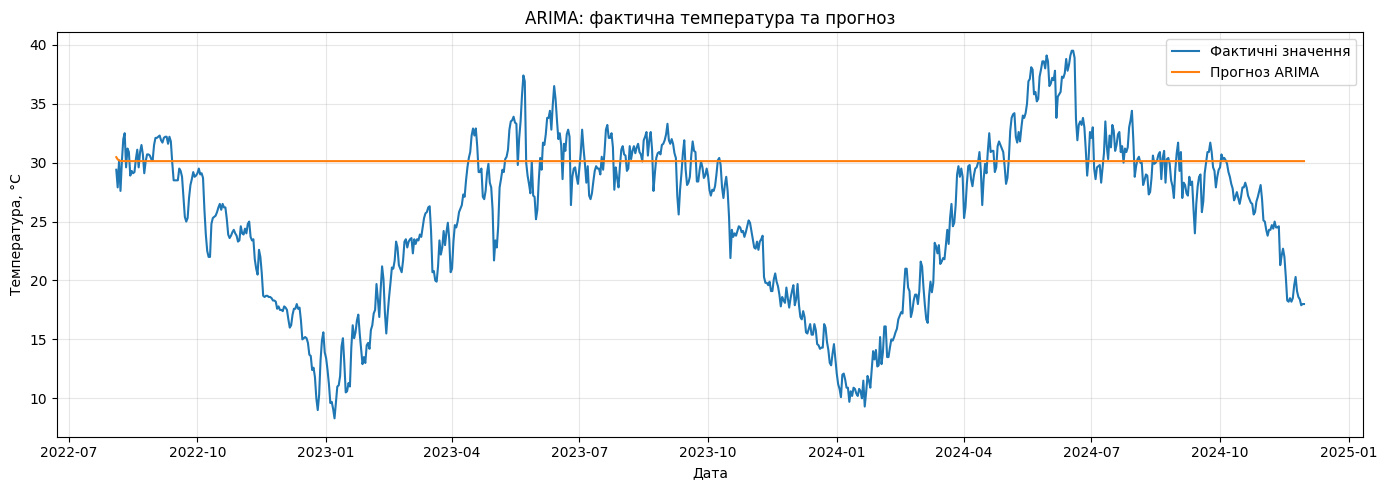

In [69]:
# Візуалізуйте фактичні значення та прогноз ARIMA
plt.figure(figsize=(14, 5))
plt.plot(test.index, test, label="Фактичні значення")
plt.plot(test.index, arima_forecast, label="Прогноз ARIMA")
plt.title("ARIMA: фактична температура та прогноз")
plt.xlabel("Дата"); plt.ylabel("Температура, °C")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

PROPHET

https://facebook.github.io/prophet/docs/quick_start.html

In [70]:
# Підготуйте дані у форматі, необхідному для Prophet
prophet_train = train.rename_axis("ds").reset_index(name="y")
prophet_test = test.rename_axis("ds").reset_index(name="y")
display(prophet_train.head())

,ds,y
0,2013-04-14,28.7
1,2013-04-15,28.6
2,2013-04-16,31.7
3,2013-04-17,29.9
4,2013-04-18,30.6


In [71]:
# Створіть та навчіть модель Prophet
try:
    from prophet import Prophet
except ImportError:
    %pip -q install prophet
    from prophet import Prophet

prophet_model = Prophet(daily_seasonality=False, weekly_seasonality=True, yearly_seasonality=True)
prophet_model.fit(prophet_train)
print("Модель Prophet навчена.")

Модель Prophet навчена.


Прогноз

In [72]:
# Побудуйте прогноз Prophet для тестового періоду
prophet_future = pd.DataFrame({"ds": prophet_test["ds"]})
prophet_result = prophet_model.predict(prophet_future)
prophet_forecast = pd.Series(prophet_result["yhat"].to_numpy(), index=test.index, name="Prophet")
display(prophet_result[["ds", "yhat", "yhat_lower", "yhat_upper"]].head())


,ds,yhat,yhat_lower,yhat_upper
0,2022-08-04,30.472997,28.039392,33.029136
1,2022-08-05,30.501332,27.892312,33.055284
2,2022-08-06,30.522214,27.997462,33.036490
3,2022-08-07,30.534157,27.977171,32.887021
4,2022-08-08,30.675759,28.334267,33.263117


In [73]:
# Обчисліть MAE, RMSE, MAPE для Prophet
metrics["Prophet"] = calculate_metrics(test, prophet_forecast)
display(pd.DataFrame([metrics["Prophet"]], index=["Prophet"]).round(3))

,MAE,RMSE,"MAPE, %"
Prophet,2.067,2.646,9.342


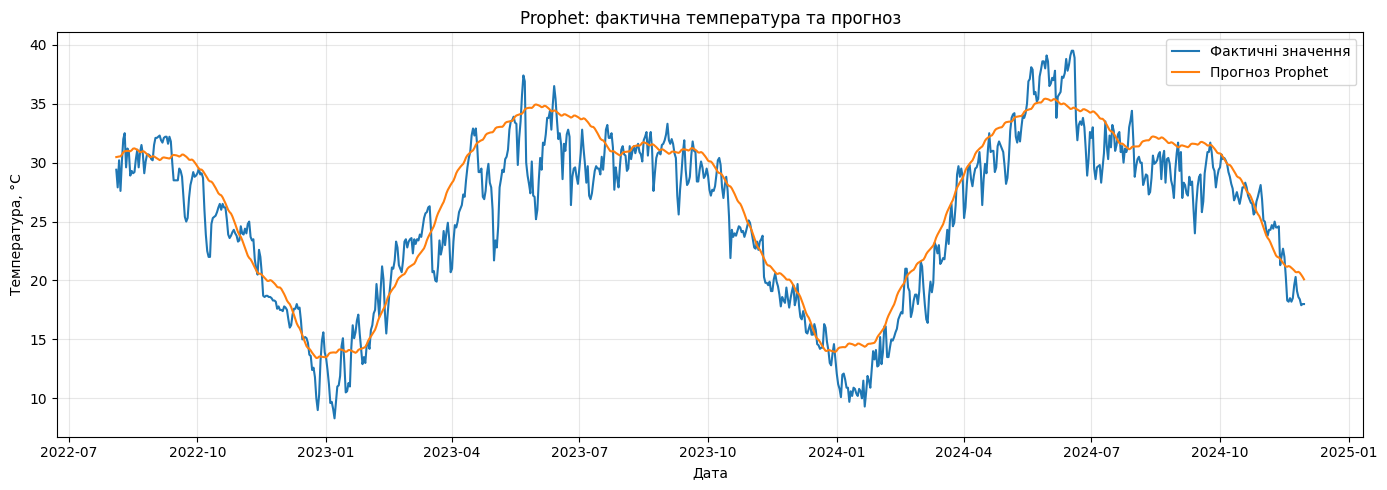

In [74]:
# Візуалізуйте фактичні значення та прогноз Prophet
plt.figure(figsize=(14, 5))
plt.plot(test.index, test, label="Фактичні значення")
plt.plot(test.index, prophet_forecast, label="Прогноз Prophet")
plt.title("Prophet: фактична температура та прогноз")
plt.xlabel("Дата"); plt.ylabel("Температура, °C")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

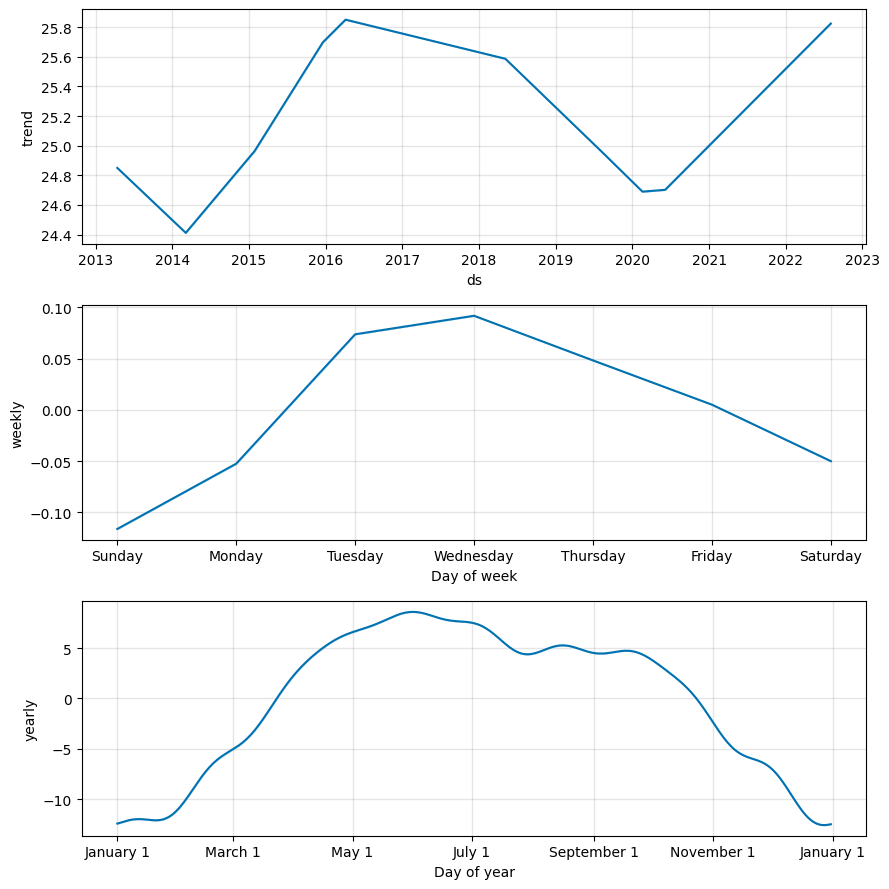

In [75]:
# Побудуйте компоненти моделі Prophet
fig = prophet_model.plot_components(prophet_model.predict(prophet_model.make_future_dataframe(periods=0)))
plt.tight_layout(); plt.show()

ПІДГОТОВКА ДАНИХ ДЛЯ LSTM

In [78]:
# Масштабуйте часовий ряд та сформуйте послідовності для LSTM
scaler = MinMaxScaler()
train_scaled = scaler.fit_transform(train.to_numpy().reshape(-1, 1))
look_back = 30

def make_sequences(data, look_back=30):
    X, y_out = [], []
    for i in range(look_back, len(data)):
        X.append(data[i-look_back:i, 0])
        y_out.append(data[i, 0])
    return np.array(X), np.array(y_out)

X_train, y_train = make_sequences(train_scaled, look_back)
X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
print("X_train:", X_train.shape, "y_train:", y_train.shape)

X_train: (3369, 30, 1) y_train: (3369,)


In [79]:
# Розділіть послідовності на тренувальну та тестову вибірки без перемішування
combined = pd.concat([train, test])
combined_scaled = scaler.transform(combined.to_numpy().reshape(-1, 1))
test_start = len(train)
X_test, y_test_scaled = [], []
for i in range(test_start, len(combined_scaled)):
    X_test.append(combined_scaled[i-look_back:i, 0])
    y_test_scaled.append(combined_scaled[i, 0])
X_test = np.array(X_test).reshape((-1, look_back, 1))
y_test_scaled = np.array(y_test_scaled)
print("X_test:", X_test.shape, "y_test:", y_test_scaled.shape)

X_test: (850, 30, 1) y_test: (850,)


In [80]:
# Побудуйте архітектуру LSTM-моделі та скомпілюйте її
lstm_model = Sequential([
    LSTM(32, input_shape=(look_back, 1)),
    Dropout(0.1),
    Dense(16, activation="relu"),
    Dense(1)
])
lstm_model.compile(optimizer="adam", loss="mse")
lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,897 (19.13 KB)

 Trainable params: 4,897 (19.13 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/12
95/95 ━━━━━━━━━━━━━━━━━━━━ 8s 14ms/step - loss: 0.0584 - val_loss: 0.0057
Epoch 2/12
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0071 - val_loss: 0.0039
Epoch 3/12
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0061 - val_loss: 0.0038
Epoch 4/12
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0053 - val_loss: 0.0036
Epoch 5/12
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0047 - val_loss: 0.0035
Epoch 6/12
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0044 - val_loss: 0.0034
Epoch 7/12
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0043 - val_loss: 0.0033
Epoch 8/12
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0040 - val_loss: 0.0033
Epoch 9/12
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0037 - val_loss: 0.0032
Epoch 10/12
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0036 - val_loss: 0.0031
Epoch 11/12
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0035 - val_loss: 0.0030
Epoch 12/12
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0033 - val_l

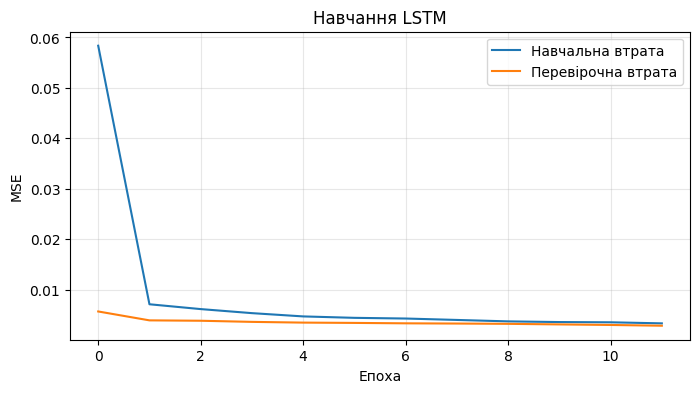

In [81]:
# Навчіть LSTM-модель
early_stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
history = lstm_model.fit(
    X_train, y_train,
    epochs=12,
    batch_size=32,
    validation_split=0.1,
    callbacks=[early_stop],
    shuffle=False,
    verbose=1
)
plt.figure(figsize=(8,4))
plt.plot(history.history["loss"], label="Навчальна втрата")
plt.plot(history.history["val_loss"], label="Перевірочна втрата")
plt.title("Навчання LSTM"); plt.xlabel("Епоха"); plt.ylabel("MSE")
plt.legend(); plt.grid(alpha=.3); plt.show()

In [82]:
# Виведіть структуру LSTM-моделі
lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,693 (57.40 KB)

 Trainable params: 4,897 (19.13 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 9,796 (38.27 KB)

In [86]:
# Отримайте прогноз LSTM та виконайте зворотне масштабування
lstm_scaled_pred = lstm_model.predict(X_test, verbose=0)
lstm_forecast_values = scaler.inverse_transform(lstm_scaled_pred).ravel()
lstm_forecast = pd.Series(lstm_forecast_values, index=test.index, name="LSTM")
display(lstm_forecast.head())

,LSTM
DATE,
2022-08-04,29.339634
2022-08-05,29.268585
2022-08-06,28.813354
2022-08-07,29.073006
2022-08-08,28.575521


In [85]:
# Сформуйте часові мітки для тестового прогнозу LSTM
print("Кількість прогнозів:", len(lstm_forecast))
print("Період прогнозу:", lstm_forecast.index.min().date(), "—", lstm_forecast.index.max().date())

Кількість прогнозів: 850
Період прогнозу: 2022-08-04 — 2024-11-30


In [88]:
# Обчисліть MAE, RMSE, MAPE для LSTM
metrics["LSTM"] = calculate_metrics(test, lstm_forecast)
display(pd.DataFrame([metrics["LSTM"]], index=["LSTM"]).round(3))

,MAE,RMSE,"MAPE, %"
LSTM,1.281,1.639,5.464


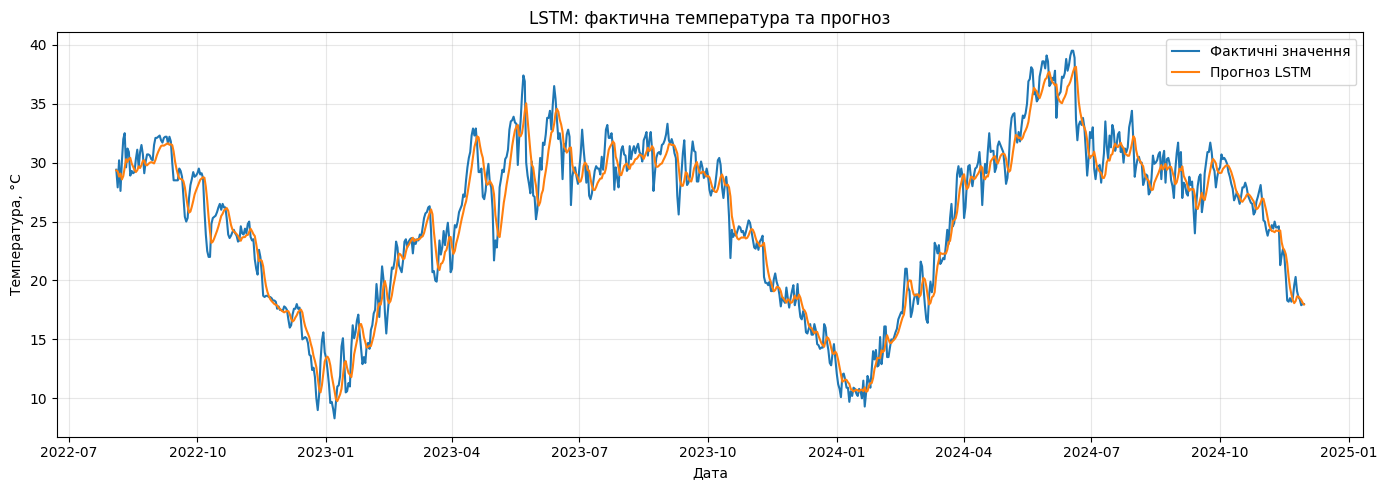

In [89]:
# Візуалізуйте фактичні значення та прогноз LSTM
plt.figure(figsize=(14, 5))
plt.plot(test.index, test, label="Фактичні значення")
plt.plot(test.index, lstm_forecast, label="Прогноз LSTM")
plt.title("LSTM: фактична температура та прогноз")
plt.xlabel("Дата"); plt.ylabel("Температура, °C")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

Порівняння моделей

,MAE,RMSE,"MAPE, %"
LSTM,1.281,1.639,5.464
Prophet,2.067,2.646,9.342
ARIMA,6.208,8.420,35.866


Найкраща модель за RMSE: LSTM


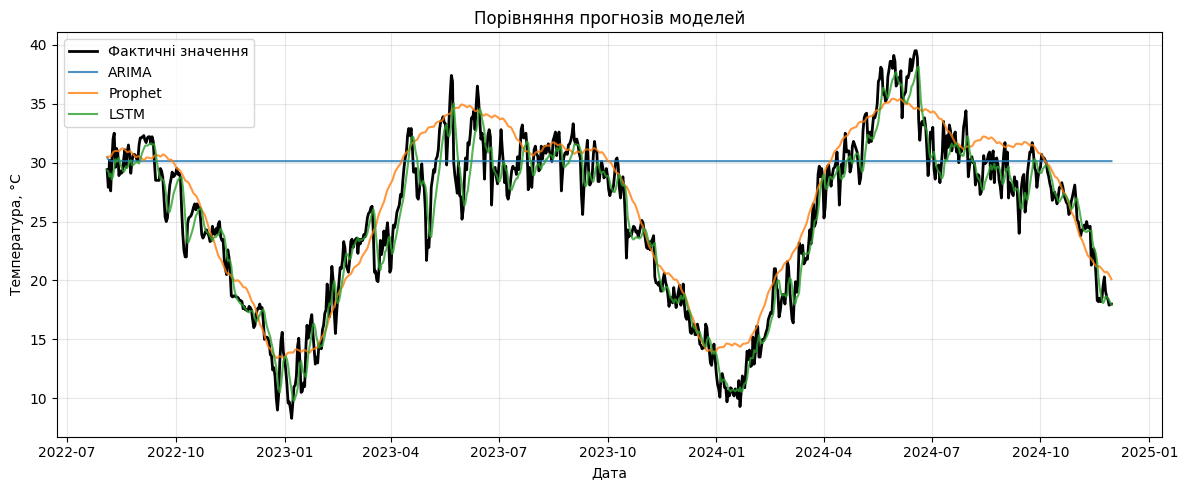

In [90]:
# Створіть підсумкову таблицю MAE, RMSE, MAPE для ARIMA, Prophet та LSTM
# Порівняйте моделі за отриманими результатами
metrics_df = pd.DataFrame(metrics).T[["MAE", "RMSE", "MAPE, %"]].sort_values("RMSE")
display(metrics_df.round(3))
best_model = metrics_df["RMSE"].idxmin()
print(f"Найкраща модель за RMSE: {best_model}")
plt.figure(figsize=(12, 5))
plt.plot(test.index, test, label="Фактичні значення", color="black", linewidth=2)
plt.plot(test.index, arima_forecast, label="ARIMA", alpha=.8)
plt.plot(test.index, prophet_forecast, label="Prophet", alpha=.8)
plt.plot(test.index, lstm_forecast, label="LSTM", alpha=.8)
plt.title("Порівняння прогнозів моделей")
plt.xlabel("Дата"); plt.ylabel("Температура, °C")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()


## Висновок

У роботі досліджено часовий ряд середньої добової температури в Делі за даними датасету за 2013–2024 роки. Дані було очищено, відсортовано за датою та перевірено на пропущені значення. Побудовано графіки температури, ковзного середнього, гістограму, boxplot, а також графіки ACF і PACF.

Для прогнозування використано три моделі: ARIMA, Prophet і LSTM. Їхню якість оцінено за метриками MAE, RMSE та MAPE. Найкращою вважається модель із найменшим значенням RMSE; конкретний результат визначається автоматично після виконання всіх клітинок. Отже, робота демонструє повний цикл аналізу та прогнозування часового ряду.
